# Weekly energy market dashboard

My weekly tracker for the US oil and gas market, started the week of Sept 14, 2026. Each row is one week (Saturday to Friday, labelled by the Friday). Prices are Friday settles. EIA publishes inventory data the following Wednesday and gas storage the following Thursday, so the newest row is often incomplete until then.

**How I update it each week:** run `python update_data.py`, re-run this notebook, write qualitative observations in `commentary/`, then commit.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv("data/weekly.csv", parse_dates=["week_ending"]).sort_values("week_ending")
df["brent_wti_spread"] = df["brent_settle"] - df["wti_settle"]
df["gas_injection_bcf"] = df["natgas_storage_bcf"].diff()
df["crude_change_mb"] = df["crude_stocks_mb"].diff()
df.set_index("week_ending").drop(columns="data_notes").round(2)

,wti_settle,brent_settle,henry_hub_spot,crude_stocks_mb,cushing_mb,refinery_util_pct,gasoline_stocks_mb,natgas_storage_bcf,hdd,cdd,elec_demand_gwh_day,wti_roll_date,brent_roll_date,brent_wti_spread,gas_injection_bcf,crude_change_mb
week_ending,,,,,,,,,,,,,,,,
2026-09-11,100.05,104.61,2.71,423.43,21.48,96.8,207.73,3298.0,0.0,89.20,13642.24,NaN,NaN,4.56,NaN,NaN
2026-09-18,100.30,103.87,2.97,426.40,23.75,94.0,206.05,3351.0,0.0,75.82,13284.86,NaN,NaN,3.57,53.0,2.97
2026-09-25,92.41,104.32,3.21,427.32,24.30,92.5,204.36,3415.0,0.0,45.42,12111.64,2026-09-22,NaN,11.91,64.0,0.92
2026-10-02,91.11,102.25,2.90,424.13,24.74,92.7,204.74,3500.0,0.0,45.00,11730.10,NaN,2026-09-30,11.14,85.0,-3.19
2026-10-09,91.85,104.72,3.10,415.58,26.61,93.5,208.26,3567.0,0.0,41.88,11446.25,NaN,NaN,12.87,67.0,-8.56
2026-10-16,101.41,109.86,NaN,NaN,NaN,NaN,NaN,NaN,0.0,30.34,11468.48,NaN,NaN,8.45,NaN,NaN


## Latest vs prior week

In [2]:
# Latest value vs. the prior week that has data, per metric
metrics = ["wti_settle", "brent_settle", "brent_wti_spread", "henry_hub_spot", "crude_stocks_mb",
           "cushing_mb", "refinery_util_pct", "gasoline_stocks_mb", "natgas_storage_bcf"]
rows = []
for m in metrics:
    s = df.set_index("week_ending")[m].dropna()
    if len(s) >= 2:
        rows.append({"metric": m, "as_of": s.index[-1].date(), "latest": s.iloc[-1], "prior": s.iloc[-2], "change": s.iloc[-1] - s.iloc[-2]})
    elif len(s) == 1:
        rows.append({"metric": m, "as_of": s.index[-1].date(), "latest": s.iloc[-1], "prior": None, "change": None})
pd.DataFrame(rows).set_index("metric").round(2)

,as_of,latest,prior,change
metric,,,,
wti_settle,2026-10-16,101.41,91.85,9.56
brent_settle,2026-10-16,109.86,104.72,5.14
brent_wti_spread,2026-10-16,8.45,12.87,-4.42
henry_hub_spot,2026-10-09,3.10,2.90,0.20
crude_stocks_mb,2026-10-09,415.58,424.13,-8.56
cushing_mb,2026-10-09,26.61,24.74,1.86
refinery_util_pct,2026-10-09,93.50,92.70,0.80
gasoline_stocks_mb,2026-10-09,208.26,204.74,3.52
natgas_storage_bcf,2026-10-09,3567.00,3500.00,67.00


## Charts

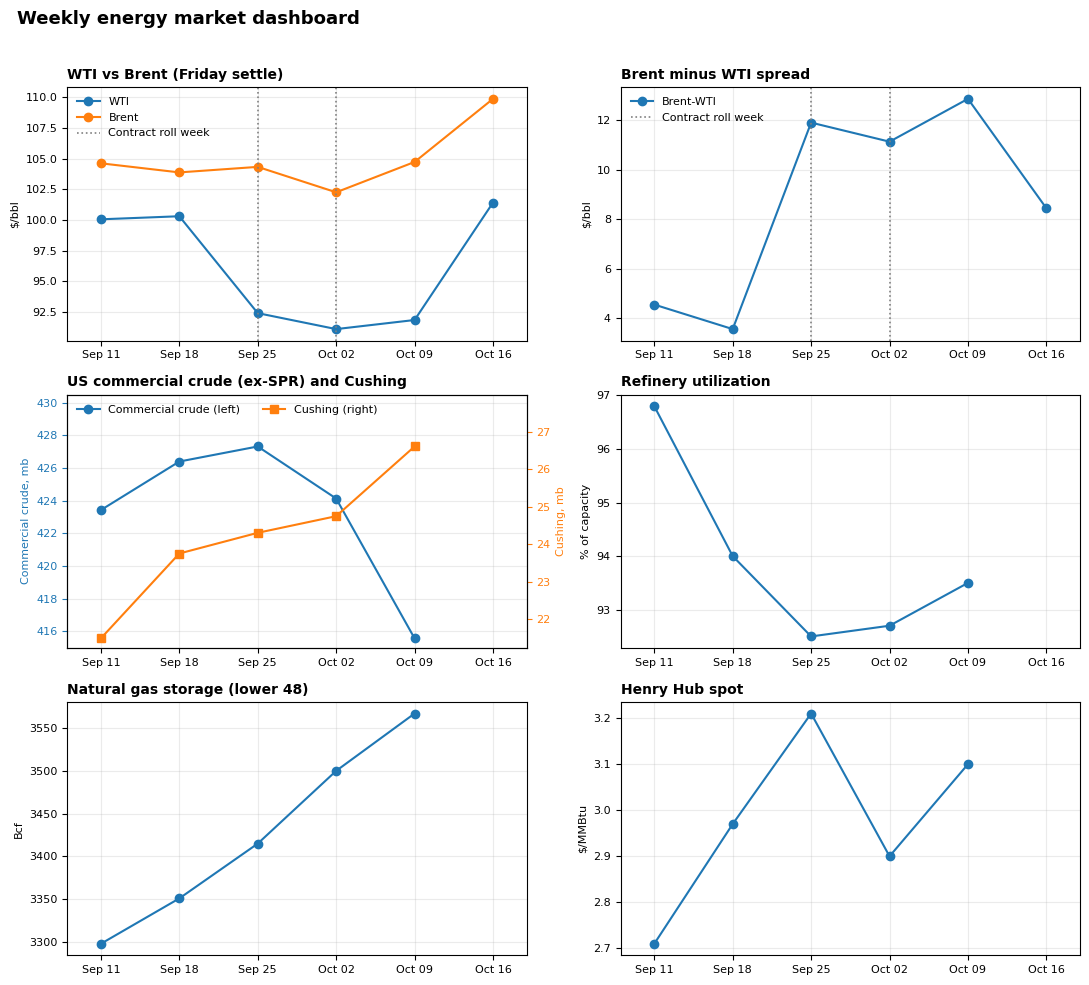

In [3]:
roll_weeks = df.loc[df["wti_roll_date"].notna() | df["brent_roll_date"].notna(), "week_ending"]

def panel(ax, title, series, ylabel="", mark_rolls=False):
    for label, col in series:
        d = df.dropna(subset=[col])
        ax.plot(d["week_ending"], d[col], marker="o", label=label)
    ax.set_title(title, fontsize=10, loc="left", fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=8)
    ax.grid(alpha=0.25)
    if mark_rolls:  # dotted line in weeks where the front WTI or Brent contract expired
        for i, wk in enumerate(roll_weeks):
            ax.axvline(wk, color="grey", ls=":", lw=1.2, label="Contract roll week" if i == 0 else None)
    ax.set_xticks(df["week_ending"])
    ax.set_xlim(df["week_ending"].min() - pd.Timedelta(days=3), df["week_ending"].max() + pd.Timedelta(days=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(labelsize=8)
    if len(series) > 1 or (mark_rolls and len(roll_weeks) > 0):
        ax.legend(fontsize=8, frameon=False)

fig, axes = plt.subplots(3, 2, figsize=(11, 10))
panel(axes[0, 0], "WTI vs Brent (Friday settle)", [("WTI", "wti_settle"), ("Brent", "brent_settle")], "$/bbl", mark_rolls=True)
panel(axes[0, 1], "Brent minus WTI spread", [("Brent-WTI", "brent_wti_spread")], "$/bbl", mark_rolls=True)
panel(axes[1, 0], "US commercial crude (ex-SPR) and Cushing", [("Commercial crude (left)", "crude_stocks_mb")], "million bbl")
ax2 = axes[1, 0].twinx()
d = df.dropna(subset=["cushing_mb"]); ax2.plot(d["week_ending"], d["cushing_mb"], marker="s", color="tab:orange", label="Cushing (right)")
ax2.set_ylabel("Cushing, mb", fontsize=8); ax2.tick_params(labelsize=8); h1, l1 = axes[1, 0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
for a in (axes[1, 0], ax2):  # headroom so the legend never covers data
    lo, hi = a.get_ylim(); a.set_ylim(lo, hi + 0.2 * (hi - lo))
axes[1, 0].legend(h1 + h2, l1 + l2, fontsize=8, frameon=False, loc="upper left", ncol=2)
axes[1, 0].set_ylabel("Commercial crude, mb", color="tab:blue", fontsize=8); axes[1, 0].tick_params(axis="y", colors="tab:blue", labelsize=8)
ax2.set_ylabel("Cushing, mb", color="tab:orange", fontsize=8); ax2.tick_params(axis="y", colors="tab:orange", labelsize=8)
panel(axes[1, 1], "Refinery utilization", [("Utilization", "refinery_util_pct")], "% of capacity")
panel(axes[2, 0], "Natural gas storage (lower 48)", [("Working gas", "natgas_storage_bcf")], "Bcf")
panel(axes[2, 1], "Henry Hub spot", [("Henry Hub", "henry_hub_spot")], "$/MMBtu")
fig.suptitle("Weekly energy market dashboard", fontsize=13, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("docs/preview.png", dpi=150, bbox_inches="tight")
plt.show()

## How I read it

- **WTI vs Brent and the spread:** a wider Brent premium usually means seaborne or Middle East risk is being priced more than US inland balances. Weeks in which the front WTI or Brent contract expired are marked with a dotted line on the price charts, so I can separate a real move from a roll.
- **Crude stocks and Cushing:** a draw is the bullish reflex, but I ask whether imports, exports or refinery runs caused it. Low Cushing tightens the WTI front spreads directly.
- **Refinery utilization:** very high means little slack for outages, and the autumn drop is usually maintenance season.
- **Gas storage vs Henry Hub:** I compare each injection to the five-year average, because the surplus or deficit is what the price is reacting to.
- **HDD/CDD and electricity demand:** weather drives power burn and heating demand, which feeds back into gas.

My weekly write-ups are in `commentary/`.